# Lab — EDA Bivariate Analysis: Amazon UK Product Insights

In this lab, I will explore Amazon UK product data to understand how product categories, prices, ratings, and best-seller status relate to each other.

The goal is to identify useful patterns in product performance and pricing that could support business decisions.

In [2]:
import pandas as pd

file_path = r"C:\Users\berta\OneDrive\Desktop\IRONHACK\WEEK 1\amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(file_path)

df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
df.info()


Dataset shape: (2443651, 9)

Column names:
['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller', 'boughtInLastMonth', 'category']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [4]:
best_seller_crosstab = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

best_seller_crosstab.head()


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [5]:
best_seller_rate = (
    best_seller_crosstab[True]
    / best_seller_crosstab.sum(axis=1)
    * 100
).sort_values(ascending=False)

best_seller_rate.head(10)


category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
Billiard, Snooker & Pool          3.212851
Pet Supplies                      3.020028
Home Brewing & Wine Making        2.845528
Wind Instruments                  2.800000
Mirrors                           2.800000
dtype: float64

In [7]:
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(best_seller_crosstab)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.10f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 36540.20
P-value: 0.0000000000
Degrees of freedom: 295


In [8]:
import numpy as np

n = best_seller_crosstab.to_numpy().sum()
min_dimension = min(best_seller_crosstab.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1223


In [11]:
import matplotlib.pyplot as plt

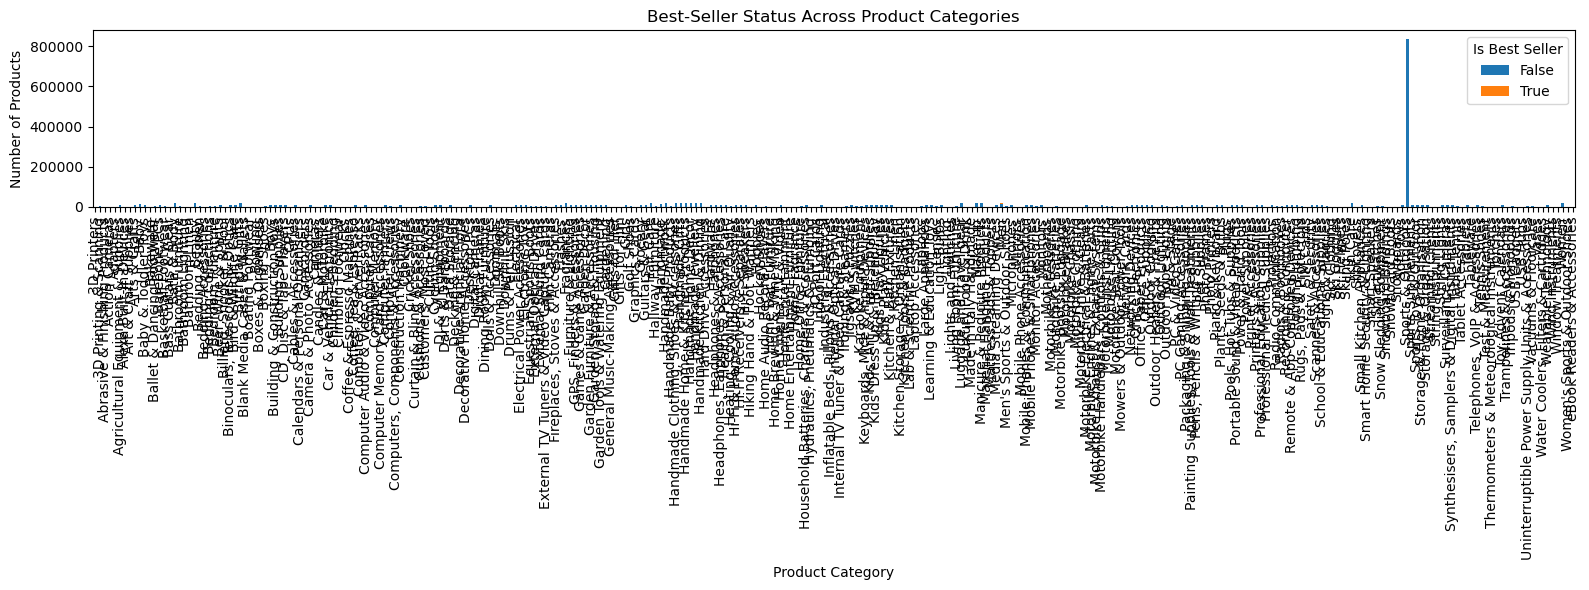

In [12]:
best_seller_crosstab.plot(
    kind="bar",
    stacked=True,
    figsize=(16, 6)
)

plt.title("Best-Seller Status Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=90)
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()

In [13]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 9.99
Q3: 45.99
IQR: 36.0
Lower bound: -44.01
Upper bound: 99.99000000000001


In [14]:
df_clean = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
].copy()

print("Original dataset:", df.shape)
print("Dataset without price outliers:", df_clean.shape)
print("Products removed:", len(df) - len(df_clean))

Original dataset: (2443651, 9)
Dataset without price outliers: (2115963, 9)
Products removed: 327688


In [15]:
top_20_categories = df_clean["category"].value_counts().head(20).index

df_top20 = df_clean[
    df_clean["category"].isin(top_20_categories)
].copy()

print("Number of categories:", df_top20["category"].nunique())
print("Number of products:", len(df_top20))

Number of categories: 20
Number of products: 1033008


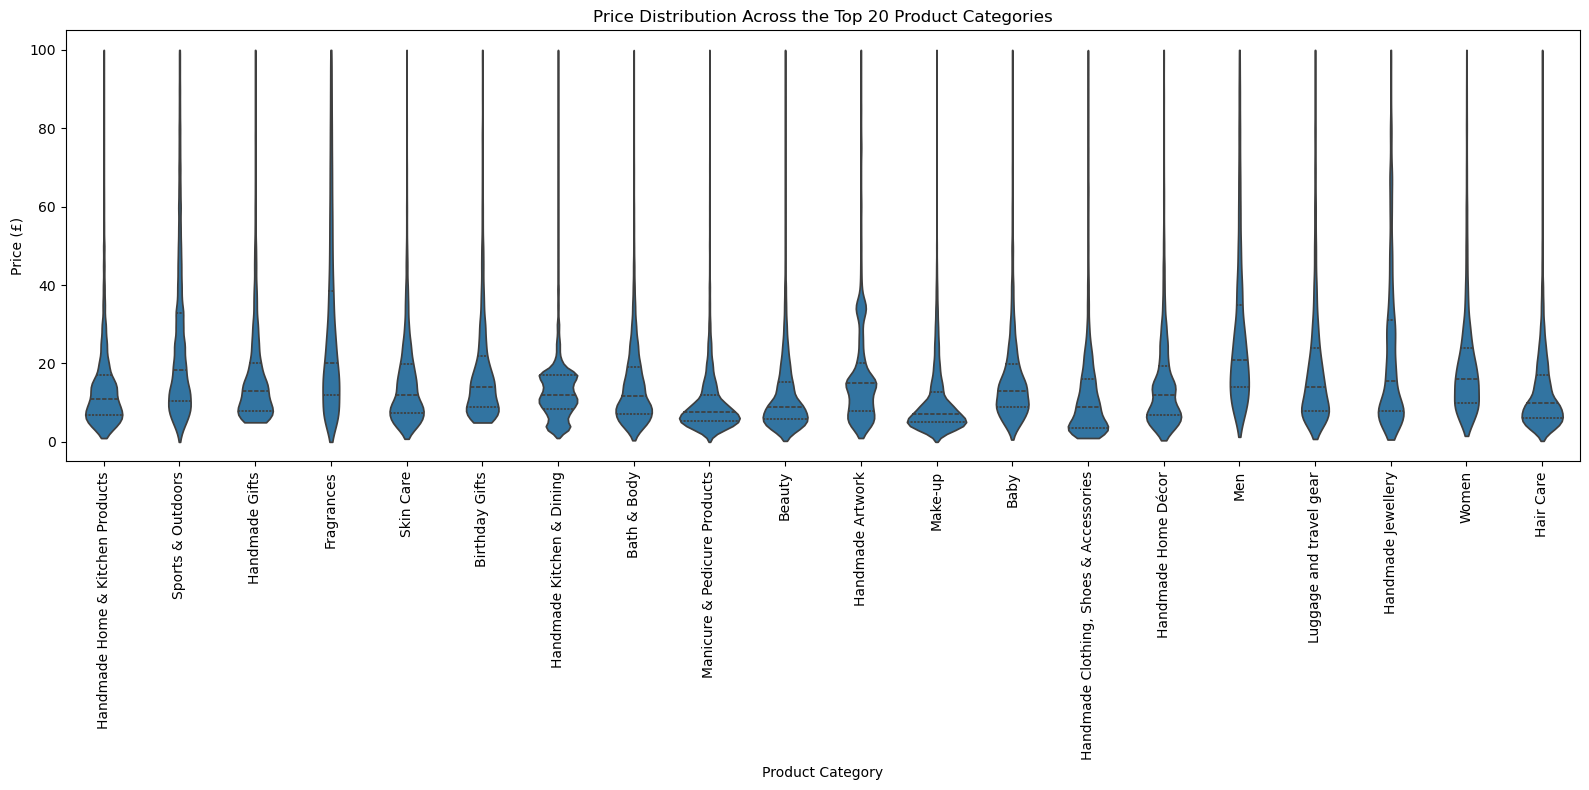

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

sns.violinplot(
    data=df_top20,
    x="category",
    y="price",
    inner="quartile",
    cut=0
)

plt.title("Price Distribution Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [17]:
median_price_by_category = (
    df_clean.groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

In [18]:
top_10_categories = df_clean["category"].value_counts().head(10).index

mean_price_by_category = (
    df_clean.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

mean_price_by_category.loc[top_10_categories].sort_values(
    ascending=False
)

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

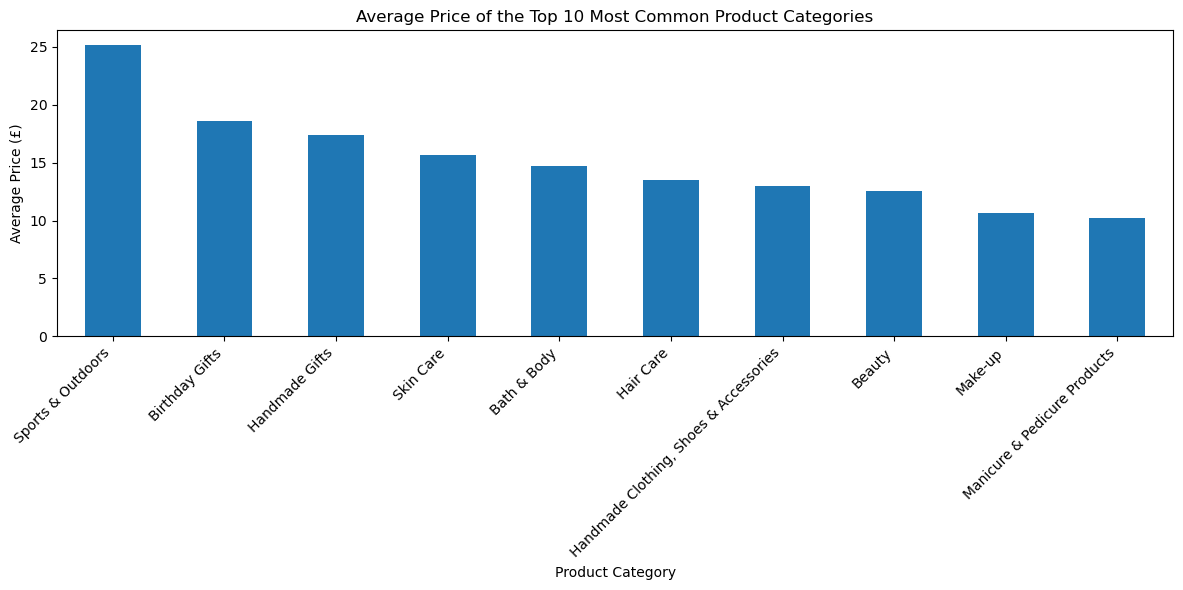

In [19]:
mean_price_top10 = (
    df_clean[df_clean["category"].isin(top_10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
mean_price_top10.plot(kind="bar")

plt.title("Average Price of the Top 10 Most Common Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
median_rating_by_category = (
    df_clean.groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head(10)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64

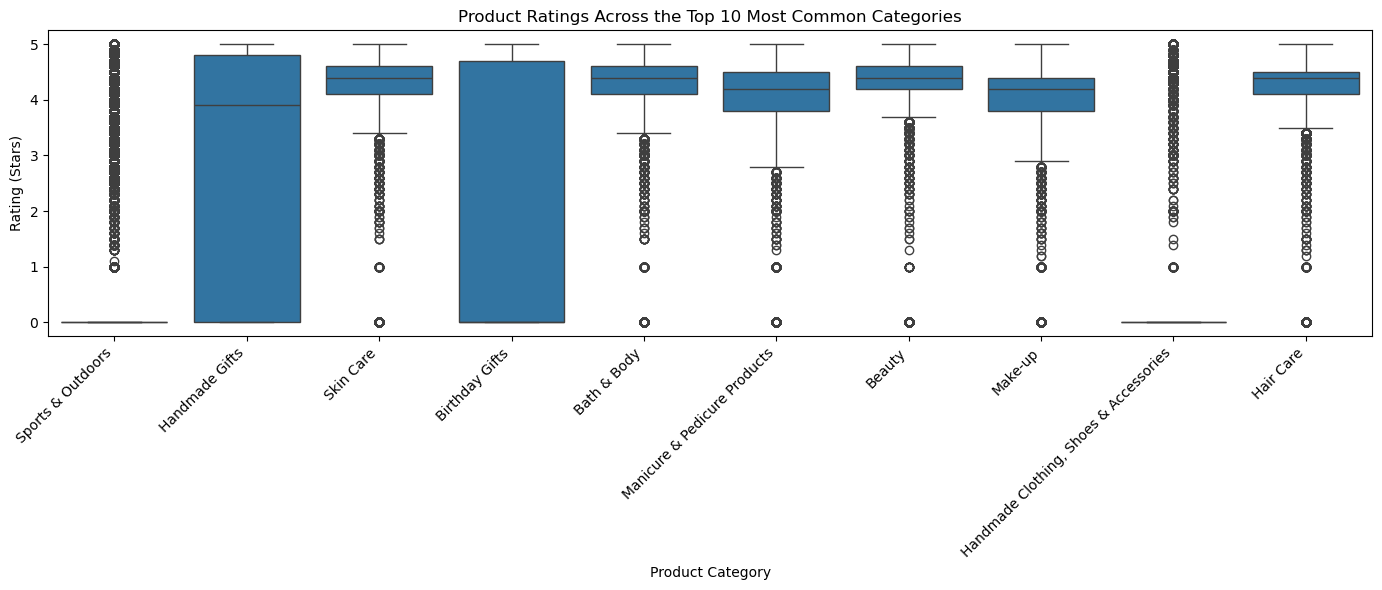

In [21]:
top_10_rating_categories = df_clean["category"].value_counts().head(10).index

df_ratings_top10 = df_clean[
    df_clean["category"].isin(top_10_rating_categories)
    & df_clean["stars"].notna()
]

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_ratings_top10,
    x="category",
    y="stars"
)

plt.title("Product Ratings Across the Top 10 Most Common Categories")
plt.xlabel("Product Category")
plt.ylabel("Rating (Stars)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
from scipy.stats import pearsonr

price_rating = df_clean[["price", "stars"]].dropna()

correlation, p_value = pearsonr(
    price_rating["price"],
    price_rating["stars"]
)

print(f"Pearson correlation: {correlation:.4f}")
print(f"P-value: {p_value:.10f}")

Pearson correlation: -0.0777
P-value: 0.0000000000


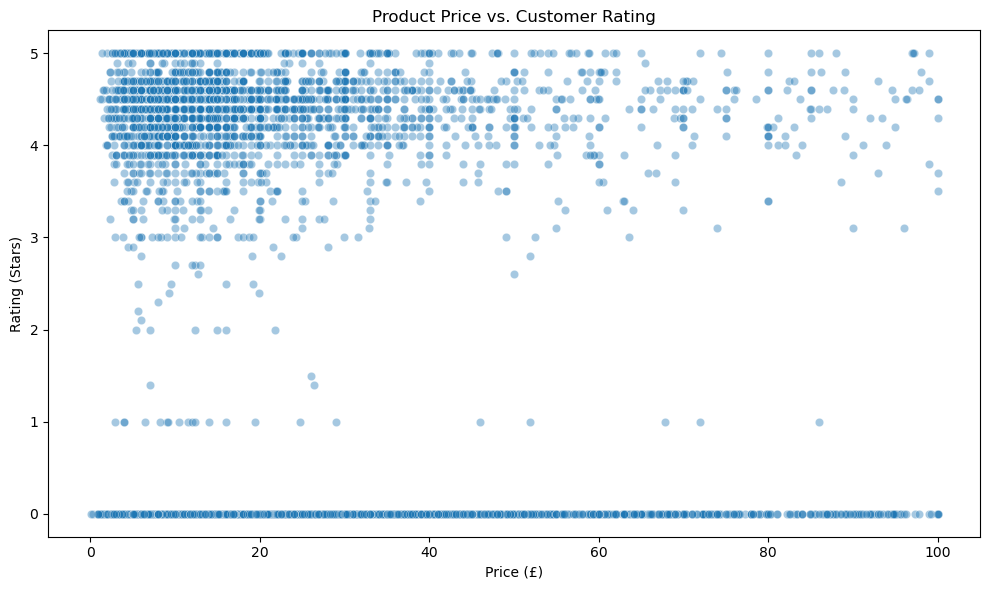

In [23]:
sample_data = price_rating.sample(
    n=5000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_data,
    x="price",
    y="stars",
    alpha=0.4
)

plt.title("Product Price vs. Customer Rating")
plt.xlabel("Price (£)")
plt.ylabel("Rating (Stars)")
plt.tight_layout()
plt.show()